In [1]:
from google.colab import files

uploaded = files.upload()

Saving CodeAlpha_Web_Scraping.csv to CodeAlpha_Web_Scraping.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [3]:
df = pd.read_csv("CodeAlpha_Web_Scraping.csv")

df.head()

,Book Name,Price,Rating
0,A Light in the Attic,51.77,Three
1,Tipping the Velvet,53.74,One
2,Soumission,50.10,One
3,Sharp Objects,47.82,Four
4,Sapiens: A Brief History of Humankind,54.23,Five


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape:
(1000, 3)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Book Name  1000 non-null   object 
 1   Price      1000 non-null   float64
 2   Rating     1000 non-null   object 
dtypes: float64(1), object(2)
memory usage: 23.6+ KB

Statistical Summary:


,Price
count,1000.00000
mean,35.07035
std,14.44669
min,10.00000
25%,22.10750
50%,35.98000
75%,47.45750
max,59.99000


In [5]:
rating_count = df["Rating"].value_counts()

print(rating_count)

Rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: int64


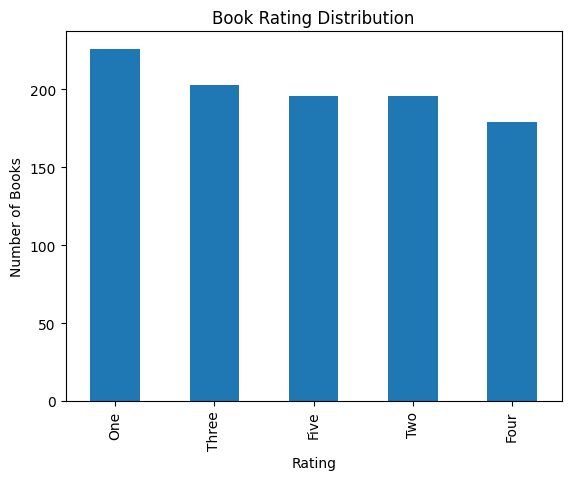

In [6]:
rating_count.plot(kind="bar")

plt.title("Book Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Books")

plt.show()

In [7]:
print("Average Price:", df["Price"].mean())

print("Highest Price:", df["Price"].max())

print("Lowest Price:", df["Price"].min())

print("Total Price:", df["Price"].sum())

Average Price: 35.07035
Highest Price: 59.99
Lowest Price: 10.0
Total Price: 35070.35


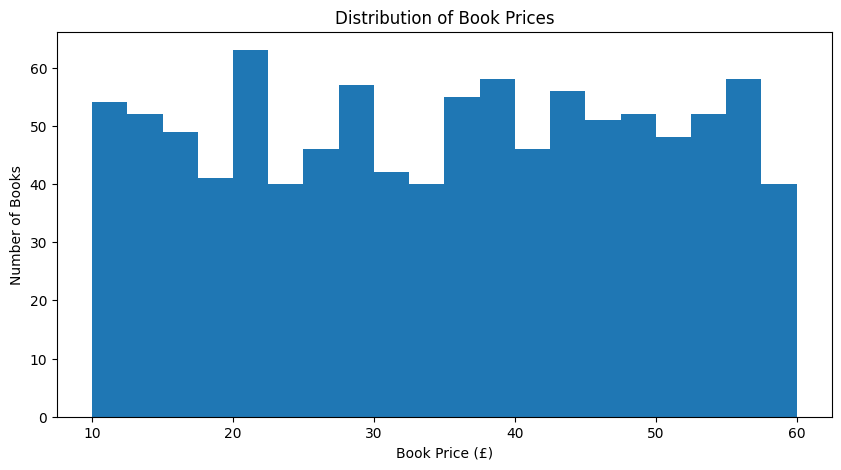

In [8]:
plt.figure(figsize=(10,5))

plt.hist(df["Price"], bins=20)

plt.title("Distribution of Book Prices")
plt.xlabel("Book Price (£)")
plt.ylabel("Number of Books")

plt.show()

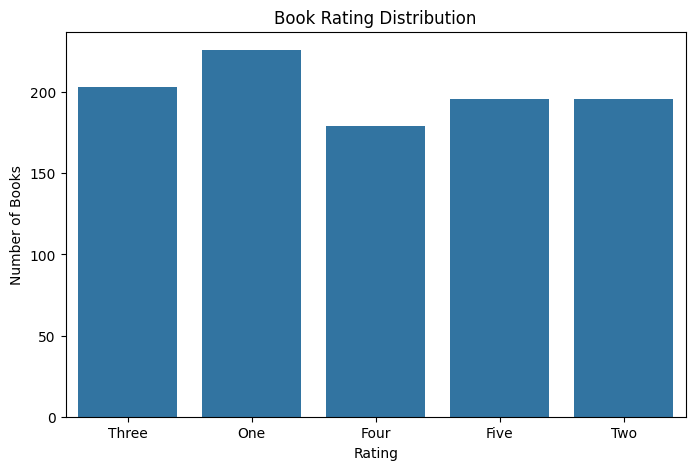

In [9]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Rating")

plt.title("Book Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Books")

plt.show()

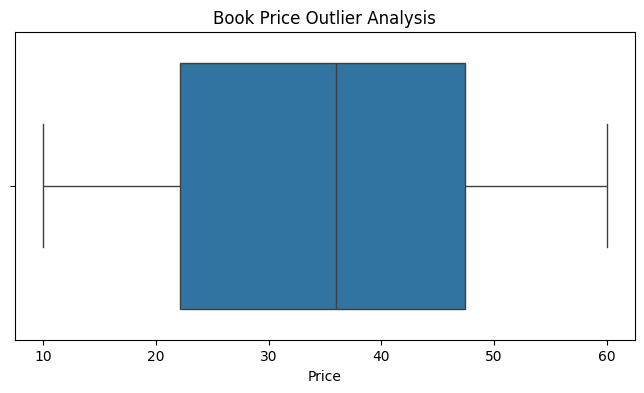

In [10]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df["Price"])

plt.title("Book Price Outlier Analysis")

plt.show()

In [11]:
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating_Number"] = df["Rating"].map(rating_map)

print(df[["Price", "Rating_Number"]].corr())

                  Price  Rating_Number
Price          1.000000       0.028166
Rating_Number  0.028166       1.000000


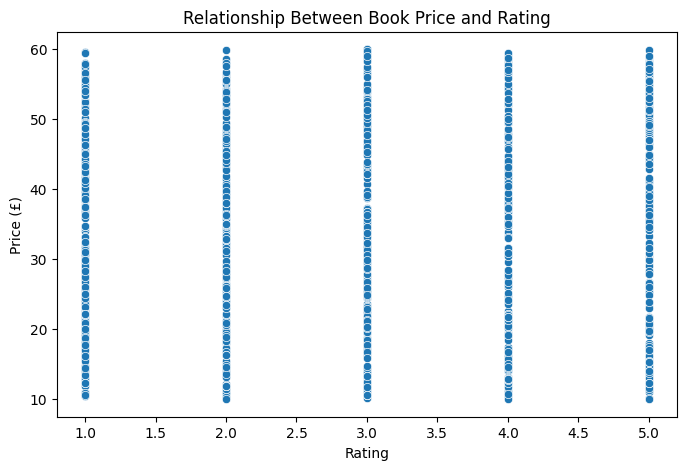

In [12]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Rating_Number",
    y="Price"
)

plt.title("Relationship Between Book Price and Rating")
plt.xlabel("Rating")
plt.ylabel("Price (£)")

plt.show()

In [13]:
print("TOTAL BOOKS:", len(df))

print("AVERAGE PRICE:", round(df["Price"].mean(), 2))

print("MAXIMUM PRICE:", df["Price"].max())

print("MINIMUM PRICE:", df["Price"].min())

print("\nMOST COMMON RATING:")
print(df["Rating"].value_counts().head(1))

TOTAL BOOKS: 1000
AVERAGE PRICE: 35.07
MAXIMUM PRICE: 59.99
MINIMUM PRICE: 10.0

MOST COMMON RATING:
Rating
One    226
Name: count, dtype: int64


In [14]:
df.to_csv("CodeAlpha_EDA_Results.csv", index=False)

print("EDA Dataset Saved Successfully!")

EDA Dataset Saved Successfully!


In [15]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.backends.backend_pdf import PdfPages

with PdfPages("CodeAlpha_EDA_Report.pdf") as pdf:

    # Page 1: Project Summary
    fig = plt.figure(figsize=(11, 8.5))

    summary = f"""
    CODEALPHA DATA ANALYTICS INTERNSHIP

    PROJECT: EXPLORATORY DATA ANALYSIS

    Dataset: Books Dataset

    Total Books: {len(df)}
    Average Price: £{df['Price'].mean():.2f}
    Highest Price: £{df['Price'].max():.2f}
    Lowest Price: £{df['Price'].min():.2f}

    Missing Values: {df.isnull().sum().sum()}
    Duplicate Records: {df.duplicated().sum()}

    Most Common Rating:
    {df['Rating'].value_counts().idxmax()}

    Total Books with Most Common Rating:
    {df['Rating'].value_counts().max()}
    """

    fig.text(0.1, 0.85, summary, fontsize=14, va="top")
    plt.axis("off")
    pdf.savefig(fig)
    plt.close()

    # Page 2: Price Distribution
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.hist(df["Price"], bins=20)
    ax.set_title("Book Price Distribution")
    ax.set_xlabel("Price (£)")
    ax.set_ylabel("Number of Books")
    pdf.savefig(fig)
    plt.close()

    # Page 3: Rating Distribution
    fig, ax = plt.subplots(figsize=(10, 6))
    order = ["One", "Two", "Three", "Four", "Five"]
    df["Rating"].value_counts().reindex(order).plot(
        kind="bar", ax=ax
    )
    ax.set_title("Book Rating Distribution")
    ax.set_xlabel("Rating")
    ax.set_ylabel("Number of Books")
    pdf.savefig(fig)
    plt.close()

    # Page 4: Price Outliers
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.boxplot(df["Price"])
    ax.set_title("Book Price Outlier Analysis")
    ax.set_ylabel("Price (£)")
    pdf.savefig(fig)
    plt.close()

print("EDA Report PDF Created Successfully!")

EDA Report PDF Created Successfully!


In [16]:
from google.colab import files

files.download("CodeAlpha_EDA_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>